# L1 -> L2

In [3]:
from romancal.pipeline import ExposurePipeline as ELP
import os
import warnings
import logging
from glob import glob as gb
    
# Ignore warnings
warnings.filterwarnings('ignore')
# Ignore INFO
logging.getLogger().setLevel(logging.CRITICAL)

# Reduce uncal files
ufiles = gb('MAST_2026-10-09T1317/Roman/*_uncal.asdf')
steps = {'source_catalog':{'skip': True}, 
         'tweakreg':{'save_abs_catalog': False}}
for ufile in ufiles:
    res = ELP.call(ufile, steps=steps, save_results=True)
    #os.rename("fit_gaiadr3_s3_ref.ecsv", ufile[:-10]+"gaiadr3.ecsv")

2026-10-09 16:36:54,789 - stpipe.step - INFO - ExposurePipeline instance created.
2026-10-09 16:36:54,790 - stpipe.step - INFO - DQInitStep instance created.
2026-10-09 16:36:54,791 - stpipe.step - INFO - SaturationStep instance created.
2026-10-09 16:36:54,791 - stpipe.step - INFO - RefPixStep instance created.
2026-10-09 16:36:54,792 - stpipe.step - INFO - DarkDecayStep instance created.
2026-10-09 16:36:54,792 - stpipe.step - INFO - WFI18TransientStep instance created.
2026-10-09 16:36:54,793 - stpipe.step - INFO - LinearityStep instance created.
2026-10-09 16:36:54,793 - stpipe.step - INFO - DarkCurrentStep instance created.
2026-10-09 16:36:54,794 - stpipe.step - INFO - RampFitStep instance created.
2026-10-09 16:36:54,795 - stpipe.step - INFO - AssignWcsStep instance created.
2026-10-09 16:36:54,795 - stpipe.step - INFO - FlatFieldStep instance created.
2026-10-09 16:36:54,796 - stpipe.step - INFO - PhotomStep instance created.
2026-10-09 16:36:54,796 - stpipe.step - INFO - Sourc

In [3]:
!conda list romancal

# packages in environment at /Users/dfadda/miniconda3/envs/flo:
#
# Name                    Version                   Build  Channel
romancal                  1.3.0.dev4+gb14e81cd2.d20261020          pypi_0    pypi


# Background files

In [1]:
from glob import glob as gb
import os
from flo.wfiskymatch import asdf2healpix
path = '/Users/dfadda/Roman/FLO_Test/Orion/'
outdir = path + 'Bkg/'
# Check if directory exists, otherwise creates it
os.makedirs(outdir, exist_ok=True)
files = sorted(gb(os.path.join(path,'*_cal.asdf')))
for file in files:
    asdf2healpix(file, outdir, savefits=False)  # NB: if True, background files are also saved as FITS files

file  r0108303005001001002_0002_wfi16_f213_cal  read in  0.5023090839385986


Median bkg rms  0.834175


/Users/dfadda/miniconda3/envs/flo/lib/python3.14/site-packages/astropy/nddata/blocks.py:160: RuntimeWarning: All-NaN slice encountered
  return func(reshaped, axis=axis)


saving in /Users/dfadda/Roman/FLO_Test/Orion/Bkg/r0108303005001001002_0002_wfi16_f213_cal.h5 time:  12.318280935287476
file  r0108303005001001002_0003_wfi16_f213_cal  read in  0.13454604148864746


Median bkg rms  0.62714887


...

/Users/dfadda/miniconda3/envs/flo/lib/python3.14/site-packages/astropy/nddata/blocks.py:160: RuntimeWarning: All-NaN slice encountered
  return func(reshaped, axis=axis)


saving in /Users/dfadda/Roman/FLO_Test/Orion/Bkg/r0108303005001001007_0001_wfi07_f213_cal.h5 time:  8.616422176361084
file  r0108303005001001007_0002_wfi07_f213_cal  read in  0.13534903526306152


Median bkg rms  0.2059972


/Users/dfadda/miniconda3/envs/flo/lib/python3.14/site-packages/astropy/nddata/blocks.py:160: RuntimeWarning: All-NaN slice encountered
  return func(reshaped, axis=axis)


saving in /Users/dfadda/Roman/FLO_Test/Orion/Bkg/r0108303005001001007_0002_wfi07_f213_cal.h5 time:  8.241155862808228


Pixel scale from wcs  [3600. 3600.]  arcsec
size of image:  (292, 292)


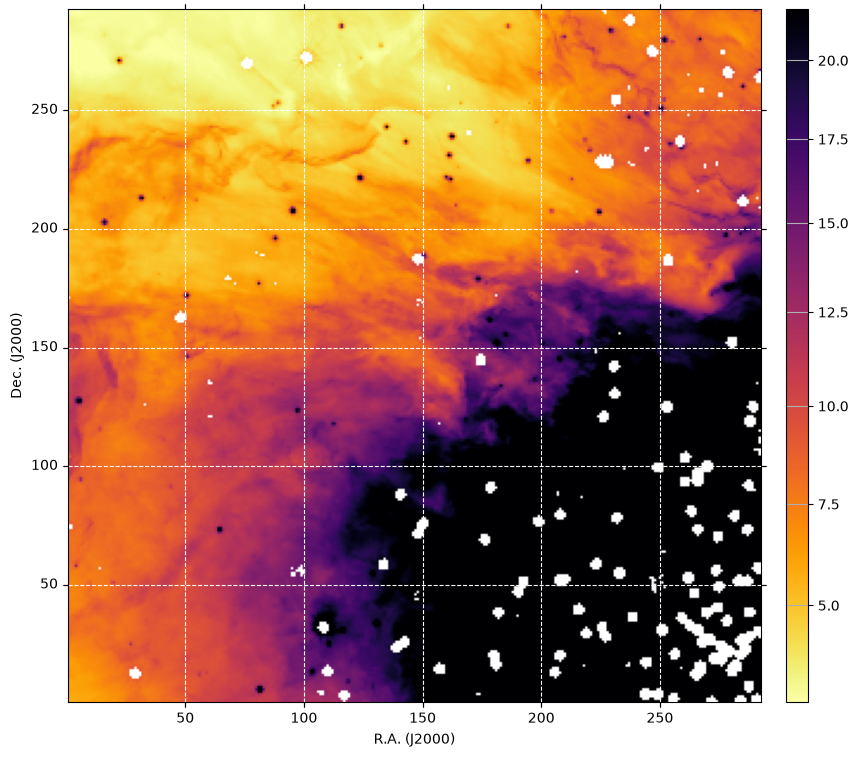

In [2]:
# Visualize background file

import matplotlib.pyplot as plt
import roman_datamodels as rdm
from astropy import visualization
from astropy.table import Table
import numpy as np
from astropy.wcs.utils import proj_plane_pixel_scales as ppps
from astropy.wcs import WCS
from astropy.io import fits

with fits.open('Bkg/r0108303005001001006_0001_wfi09_f213_cal.fits') as f:
    image = f[0].data
    header = f[0].header
wcs = WCS(header)
print('Pixel scale from wcs ', ppps(wcs)*3600, ' arcsec')
print('size of image: ', np.shape(image))
norm = visualization.ImageNormalize(image,
                                    interval=visualization.ZScaleInterval(contrast=1),
                                    stretch=visualization.AsinhStretch(a=1))

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw={'projection':wcs})
plot = ax.imshow(image, norm=norm,  origin='lower',cmap='inferno_r')
ax.coords.grid(True, color='white', ls='dashed')
ax.coords[0].set_axislabel('R.A. (J2000)')
ax.coords[1].set_axislabel('Dec. (J2000)')
cax = plt.axes([0.925, 0.11, 0.025,0.77 ])
plt.colorbar(mappable=plot, cax=cax)
plt.grid()
plt.show()

In [3]:
# Computing offsets
from flo.wfiskymatch import pixmatch
from glob import glob as gb
import os

files = sorted(gb(os.path.join(outdir,'*cal.h5')))

object = 'field'
offsets = pixmatch(files, outfile=outdir+object+'_offsets', offsets=None)

for file, offset in zip(files, offsets):
    print(file, offsets)

/Users/dfadda/Roman/FLO_Test/Orion/Bkg/r0108303005001001002_0002_wfi16_f213_cal.h5
/Users/dfadda/Roman/FLO_Test/Orion/Bkg/r0108303005001001002_0003_wfi16_f213_cal.h5
/Users/dfadda/Roman/FLO_Test/Orion/Bkg/r0108303005001001003_0002_wfi18_f213_cal.h5
/Users/dfadda/Roman/FLO_Test/Orion/Bkg/r0108303005001001006_0001_wfi09_f213_cal.h5
/Users/dfadda/Roman/FLO_Test/Orion/Bkg/r0108303005001001007_0001_wfi07_f213_cal.h5
/Users/dfadda/Roman/FLO_Test/Orion/Bkg/r0108303005001001007_0002_wfi07_f213_cal.h5
[ 0.49038122  0.21622507  1.2108749  -0.28748195 -0.62299865 -0.78495382]


In [4]:
# Add offsets to original images - create new files
from flo.wfiskymatch import addOffset
import h5py
import os

path = '/Users/dfadda/Roman/FLO_Test/Orion/'
bkgpath = path + 'Bkg/'
h5file = bkgpath + 'field_offsets.h5'
with h5py.File(h5file, 'r') as hdf5_file:
    files = hdf5_file['files'][:]
    offsets = hdf5_file['offsets'][:]

# Create new files with added offsets
outdir = path + '/Offset/'
os.makedirs(outdir, exist_ok=True)
for file, offset in zip(files,offsets):
    print(file.decode(), offset)
    L2 = path + file.decode() +'.asdf'
    addOffset(L2, offset=offset, outdir = outdir)

r0108303005001001002_0002_wfi16_f213_cal 0.4903812
r0108303005001001002_0003_wfi16_f213_cal 0.21622507
r0108303005001001003_0002_wfi18_f213_cal 1.2108749
r0108303005001001006_0001_wfi09_f213_cal -0.28748196
r0108303005001001007_0001_wfi07_f213_cal -0.62299865
r0108303005001001007_0002_wfi07_f213_cal -0.78495383


# Desaturation

In [12]:
# Get the list of coordinates at the time of the observation
from flo.simutils import gaiastars
import roman_datamodels as rdm

with rdm.open('Offset/r0108303005001001002_0002_wfi16_f213_off_cal.asdf') as dm:
    astro = dm.meta.wcs
    ra0, dec0 = astro(2044.5,2044.5)
    start_time = dm.meta.exposure.start_time

radius = 0.5  # Radius of the catalog in degrees

# Retrieve catalog and save it locally
gaia_catalog = gaiastars(ra=ra0, dec=dec0, radius=radius, star=0.5, maglim=16, obs_time=start_time)
gaia_catalog.write('gaia_catalog.ecsv', format='ascii.ecsv', overwrite=True)


**WARNING**: LOCAL JWST PRD VERSION PRDOPSSOC-073 DOESN'T MATCH THE CURRENT ONLINE VERSION PRDOPSSOC-075
Please consider updating pysiaf, e.g. pip install --upgrade pysiaf or conda update pysiaf


The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


2026-10-15 12:00:16 INFO     Query finished.


INFO: Query finished. [astroquery.utils.tap.core]


In [5]:
# Desaturate the PSFs
from flo.desaturate import desaturatePsf
from astropy.coordinates import SkyCoord
from astropy.table import Table
from glob import glob as gb

path = '/Users/dfadda/Roman/FLO_Test/Orion/Offset/'
ufiles = gb(path + 'r*_off_cal.asdf')

gaia_catalog = Table.read('gaia_catalog.ecsv')
stars = SkyCoord(gaia_catalog['ra'].value, gaia_catalog['dec'].value, unit='deg', frame = 'icrs')

for L2 in ufiles:
    desaturatePsf(L2, stars)

There are 167 bright stars which will be corrected
PSF substitution for 103 non GAIA saturated sources 
Corrected a total of 270 saturated sources
There are 45 bright stars which will be corrected
PSF substitution for 59 non GAIA saturated sources 
Corrected a total of 104 saturated sources
There are 84 bright stars which will be corrected
PSF substitution for 53 non GAIA saturated sources 
Corrected a total of 137 saturated sources
There are 154 bright stars which will be corrected
PSF substitution for 85 non GAIA saturated sources 
Corrected a total of 239 saturated sources
There are 61 bright stars which will be corrected
PSF substitution for 20 non GAIA saturated sources 
Corrected a total of 81 saturated sources
There are 104 bright stars which will be corrected
PSF substitution for 38 non GAIA saturated sources 
Corrected a total of 142 saturated sources


# Masking of bad pixels

Here we should also include possible masking of regions affected by artefacts.

In [6]:
from glob import glob as gb
import roman_datamodels as rdm
from roman_datamodels.dqflags import pixel   
import numpy as np

path = '/Users/dfadda/Roman/FLO_Test/Orion/Offset/'
ufiles = gb(path + 'r*_off_cal_us.asdf')

for ufile in ufiles:
    #print(ufile)
    outfile = ufile[:-5]+'_ok.asdf'
    with rdm.open(ufile) as dm:
        data = dm.data.copy()
        dq = dm.dq.copy()
    idx = ((data < 0) | (data > 50000)) & ((dq & pixel.DO_NOT_USE.value) == 0)
    med = np.nanmedian(data.ravel())
    print(ufile + f': {np.sum(idx)/4088**2 * 100:.2f}% negative non-masked pixels, median {med:.1f}')
    # Put data to NaN and flag pixel as do_not_use
    data[idx] = np.nan
    dq[idx] |= pixel.DO_NOT_USE.value
    # Overwrite file
    with rdm.open(ufile) as dm:
        dm.data = data
        dm.dq = dq
        dm.save(outfile)   

/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001003_0002_wfi18_f213_off_cal_us.asdf: 0.01% negative non-masked pixels, median 10.6
/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001007_0002_wfi07_f213_off_cal_us.asdf: 0.08% negative non-masked pixels, median 5.6
/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001006_0001_wfi09_f213_off_cal_us.asdf: 0.02% negative non-masked pixels, median 9.2
/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001002_0002_wfi16_f213_off_cal_us.asdf: 0.01% negative non-masked pixels, median 19.0
/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001002_0003_wfi16_f213_off_cal_us.asdf: 0.01% negative non-masked pixels, median 16.4
/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001007_0001_wfi07_f213_off_cal_us.asdf: 0.08% negative non-masked pixels, median 4.9


# Mosaic [direct]

In [5]:
# Association file
import romancal.associations.asn_from_list as asn_from_list
from glob import glob as gb

path = '/Users/dfadda/Roman/FLO_Test/Orion/Offset/'
input_files = gb(path + 'r*_ok.asdf')
product_name = 'Orion_f213'

# Create the ASN JSON object
asn = asn_from_list.asn_from_list([(i, 'science') for i in input_files], 
                                  product_name=product_name, 
                                  with_exptype=True, target='')

# Write the ASN file to disk
_, serialized = asn.dump()
with open(path+'Orion_f213_asn.json', 'w') as f:
    f.write(serialized)

In [6]:
# Mosaic without computing new offsets
from romancal.pipeline import MosaicPipeline

path = '/Users/dfadda/Roman/FLO_Test/Orion/Offset/'

steps = {'outlier_detection':{'skip':True},
         'skymatch':{'skip':True},
         'resample':{'resample_on_skycell':False},
         'source_catalog':{'skip':True},
        }

result = MosaicPipeline.call(path+'Orion_f213_asn.json', 
                             save_results=True, resample_on_skycell=False,
                             steps=steps)

2026-10-19 11:18:58,969 - romancal.associations._association - WARNING - Cannot validate: <class 'romancal.associations._association._Association'> has no schema. Presuming OK.
2026-10-19 11:18:59,035 - CRDS - ERROR -  Error determining best reference for 'pars-mosaicpipeline'  =   Unknown reference type 'pars-mosaicpipeline'
2026-10-19 11:18:59,038 - stpipe.step - INFO - MosaicPipeline instance created.
2026-10-19 11:18:59,038 - stpipe.step - INFO - FluxStep instance created.
2026-10-19 11:18:59,039 - stpipe.step - INFO - SkyMatchStep instance created.
2026-10-19 11:18:59,039 - stpipe.step - INFO - OutlierDetectionStep instance created.
2026-10-19 11:18:59,040 - stpipe.step - INFO - ResampleStep instance created.
2026-10-19 11:18:59,040 - stpipe.step - INFO - SourceCatalogStep instance created.
2026-10-19 11:18:59,138 - stpipe.step - INFO - Step MosaicPipeline running with args ('/Users/dfadda/Roman/FLO_Test/Orion/Offset/Orion_f213_asn.json',).
2026-10-19 11:18:59,142 - stpipe.step - 

Pixel scale  1.0  pixels
Pixel scale from wcs  [0.10876549 0.10876549]  arcsec
size of skycell:  (9480, 7804)


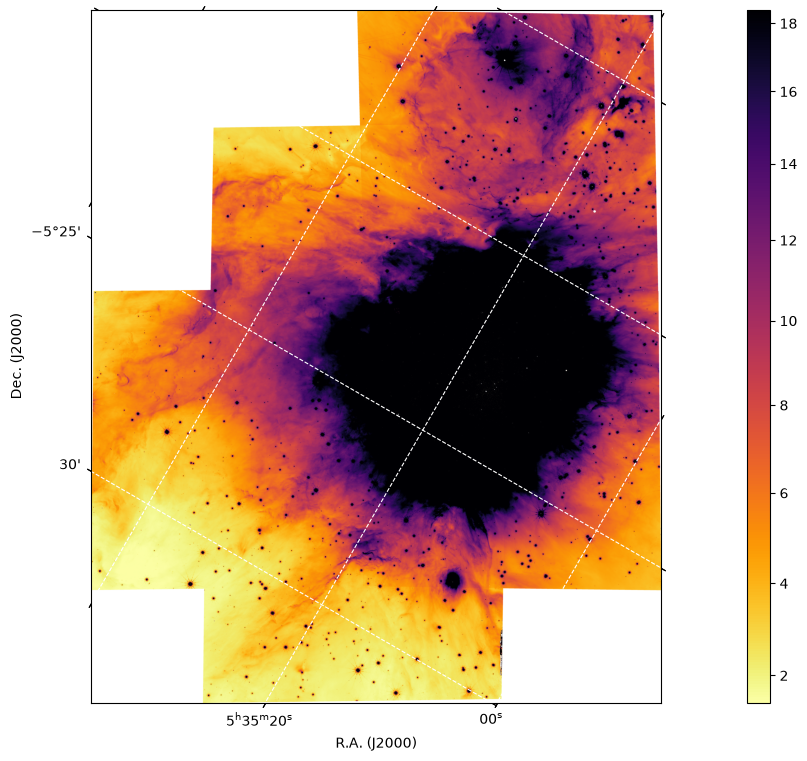

In [7]:
# Display the mosaic

# Display mosaic
import matplotlib.pyplot as plt
import roman_datamodels as rdm
from astropy import visualization
from astropy.table import Table
import numpy as np
from astropy.wcs.utils import proj_plane_pixel_scales as ppps

filename = 'Orion_f213_coadd.asdf'

with rdm.open(filename) as dm:
    wcs = dm.meta.wcs
    meta = dm.meta
    data = dm.data.copy()
    hdr = dm.meta.wcs.to_fits()[0]
    print('Pixel scale ', dm.meta.resample['pixel_scale_ratio'],' pixels')

from astropy.wcs import WCS
wcs = WCS(hdr)
print('Pixel scale from wcs ', ppps(wcs)*3600, ' arcsec')
print('size of skycell: ', np.shape(data))

norm = visualization.ImageNormalize(data,
                                    interval=visualization.ZScaleInterval(contrast=1),
                                    stretch=visualization.AsinhStretch(a=1))

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw={'projection':wcs})

plot = ax.imshow(data, norm=norm, origin='lower',cmap='inferno_r')
ax.coords.grid(True, color='white', ls='dashed')
ax.coords[0].set_axislabel('R.A. (J2000)')
ax.coords[1].set_axislabel('Dec. (J2000)')

cax = plt.axes([0.925, 0.11, 0.025,0.77 ])
plt.colorbar(mappable=plot, cax=cax)

plt.show()

Pixel scale  1.0  pixels
Pixel scale from wcs  [0.10876549 0.10876549]  arcsec
size of skycell:  (9480, 7804)


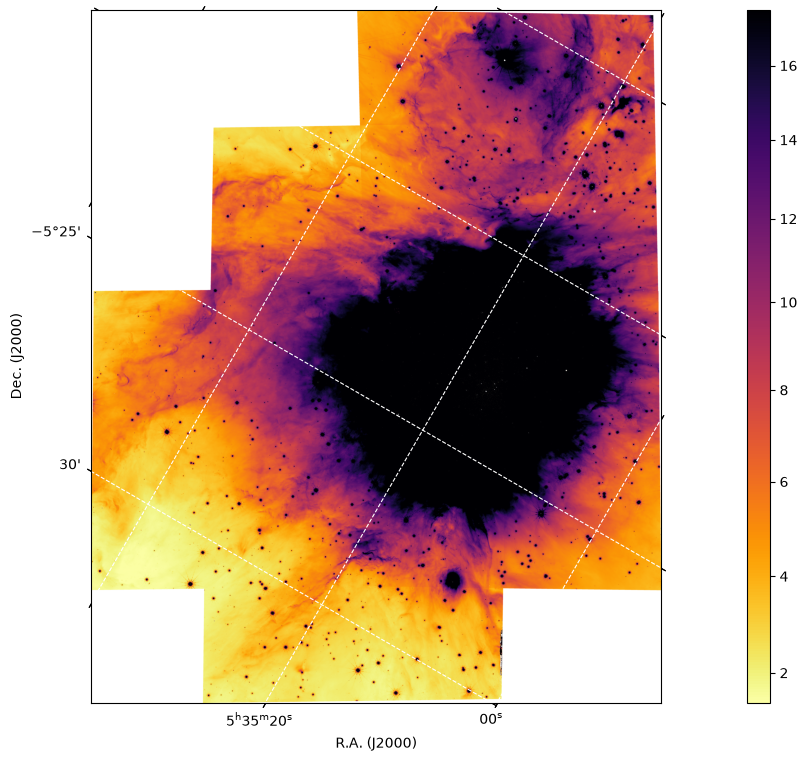

In [17]:
# Display mosaic
import matplotlib.pyplot as plt
import roman_datamodels as rdm
from astropy import visualization
from astropy.table import Table
import numpy as np
from astropy.wcs.utils import proj_plane_pixel_scales as ppps

filename = 'Orion_f213_coadd.asdf'

with rdm.open(filename) as dm:
    wcs = dm.meta.wcs
    meta = dm.meta
    data = dm.data.copy()
    hdr = dm.meta.wcs.to_fits()[0]
    print('Pixel scale ', dm.meta.resample['pixel_scale_ratio'],' pixels')

from astropy.wcs import WCS
wcs = WCS(hdr)
print('Pixel scale from wcs ', ppps(wcs)*3600, ' arcsec')
print('size of skycell: ', np.shape(data))

norm = visualization.ImageNormalize(data,
                                    interval=visualization.ZScaleInterval(contrast=1),
                                    stretch=visualization.AsinhStretch(a=1))

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw={'projection':wcs})

plot = ax.imshow(data, norm=norm, origin='lower',cmap='inferno_r')
ax.coords.grid(True, color='white', ls='dashed')
ax.coords[0].set_axislabel('R.A. (J2000)')
ax.coords[1].set_axislabel('Dec. (J2000)')

cax = plt.axes([0.925, 0.11, 0.025,0.77 ])
plt.colorbar(mappable=plot, cax=cax)

plt.show()

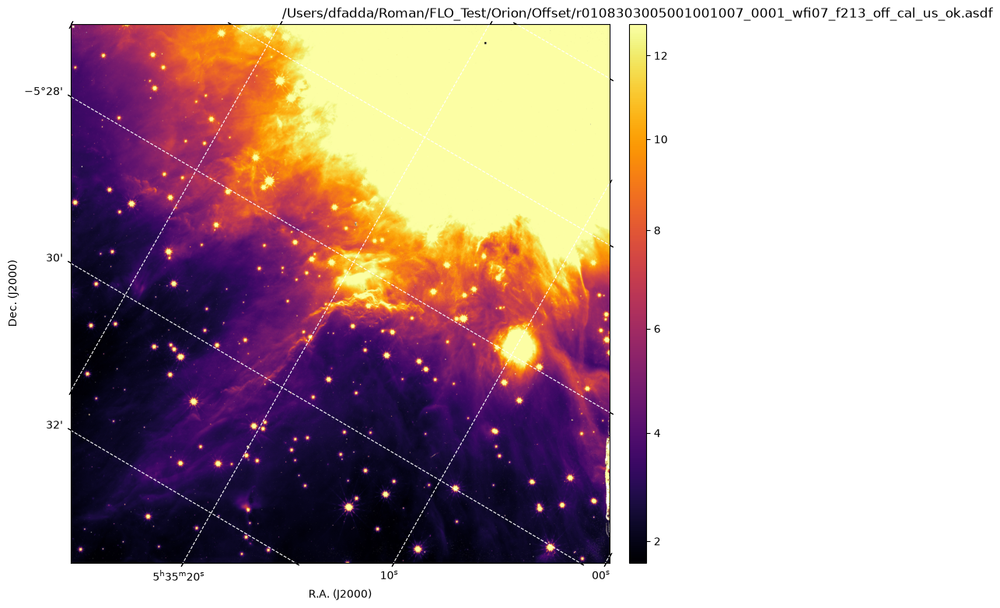

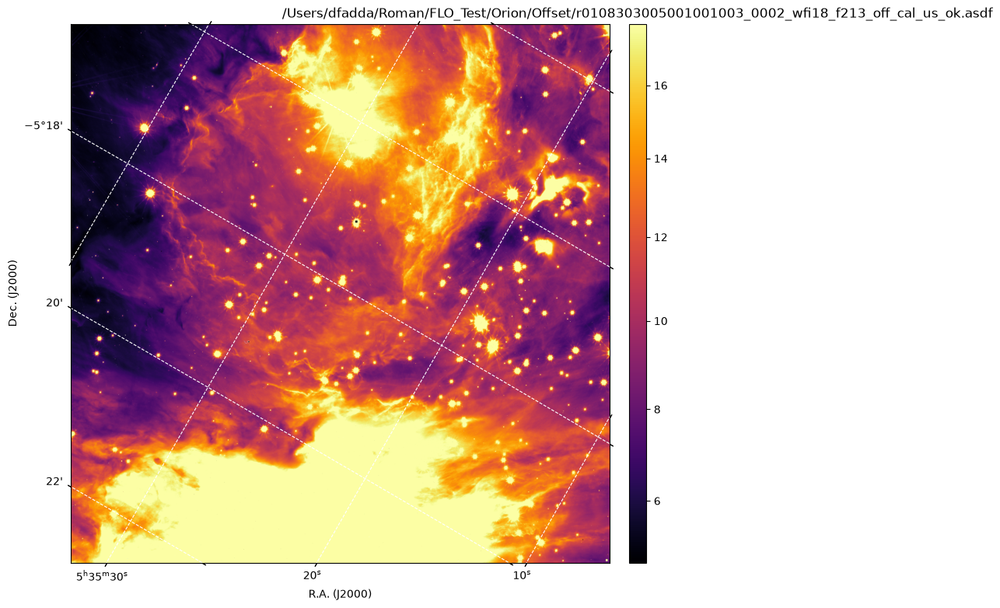

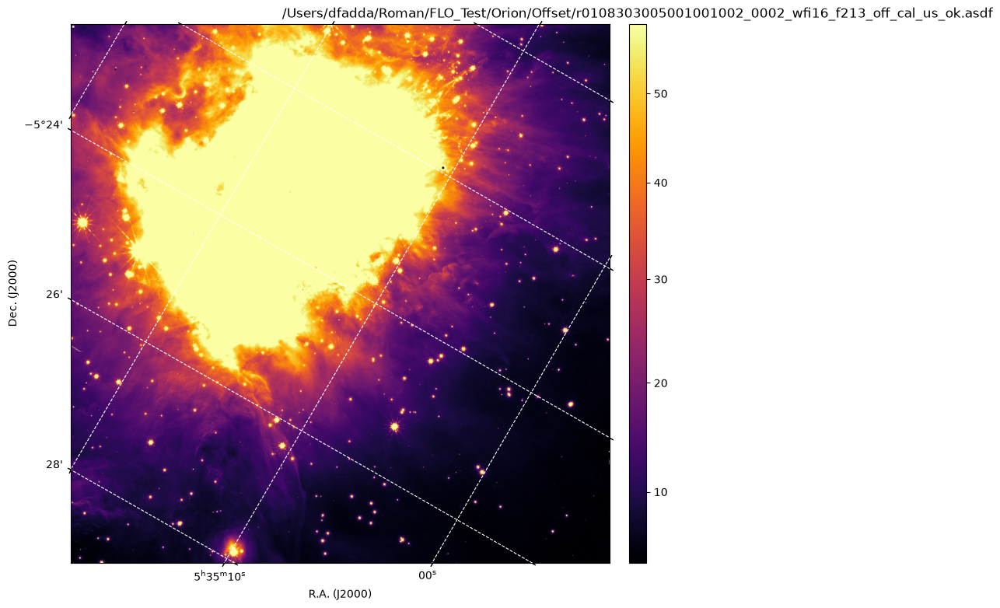

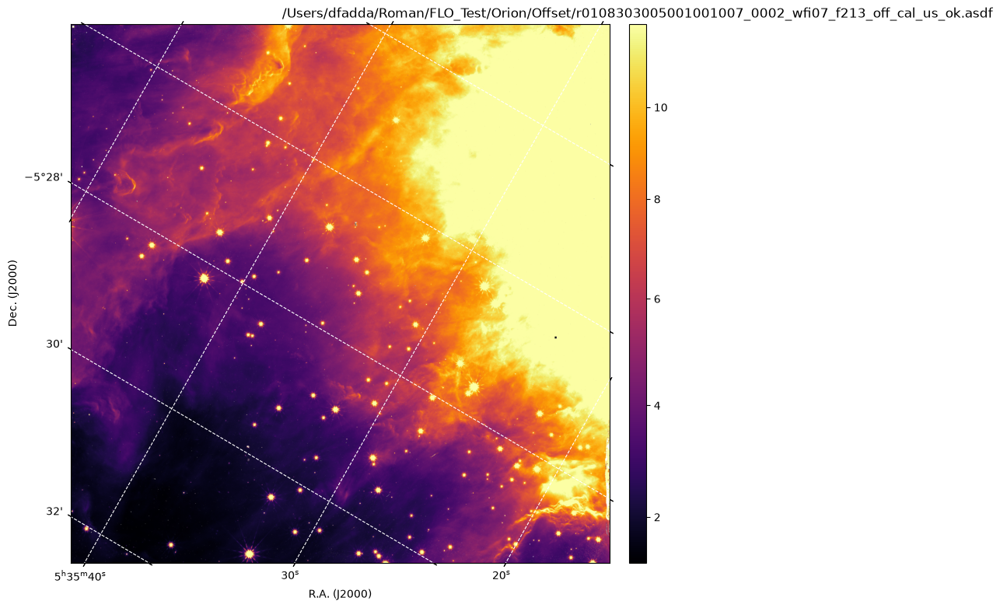

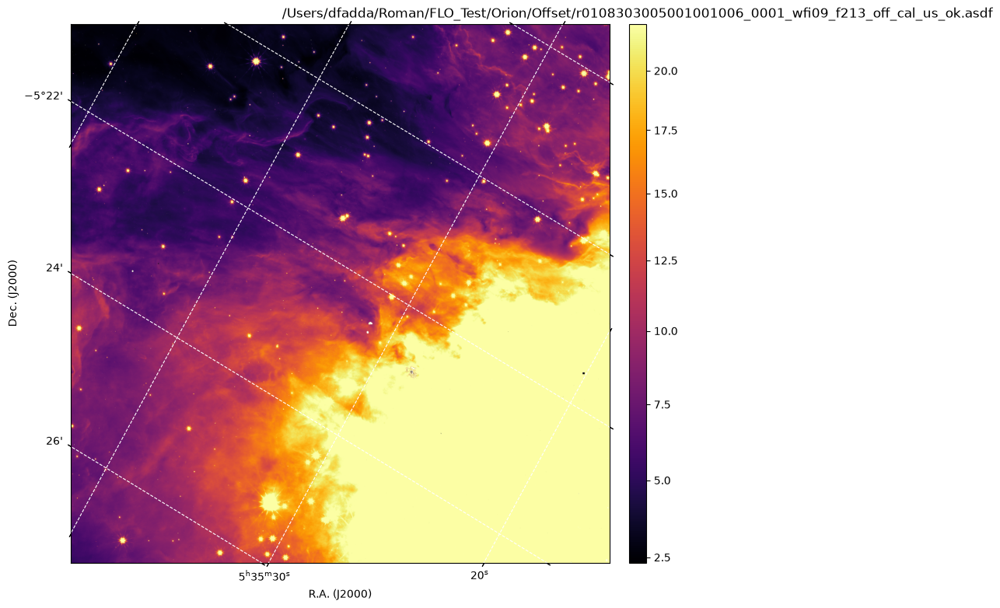

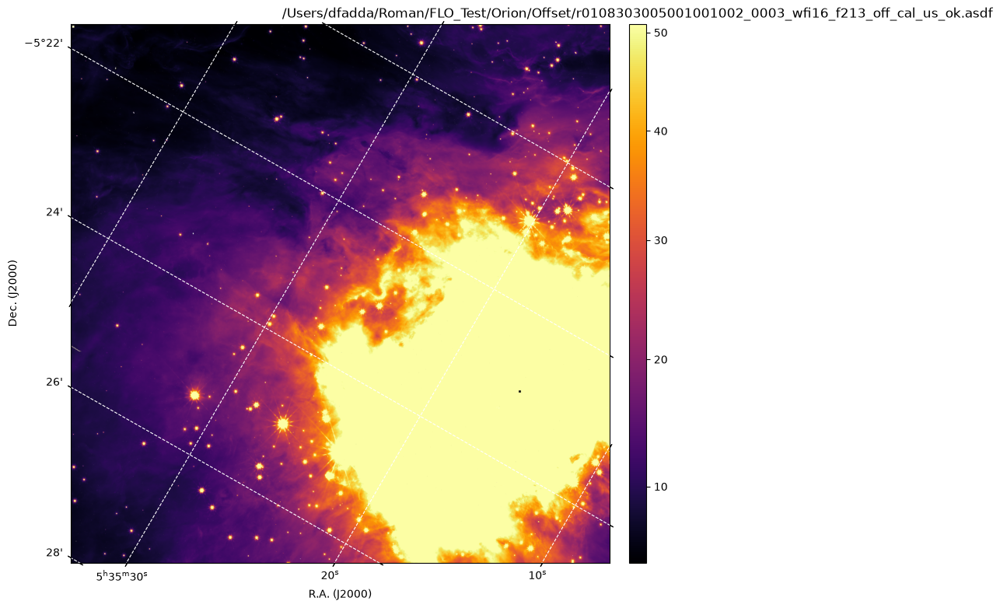

In [13]:
# Single ones
# Display mosaic
import matplotlib.pyplot as plt
import roman_datamodels as rdm
from astropy import visualization
from astropy.table import Table
import numpy as np
from astropy.wcs.utils import proj_plane_pixel_scales as ppps
from astropy.wcs import WCS

path = '/Users/dfadda/Roman/FLO_Test/Orion/Offset/'
input_files = gb(path + 'r*_ok.asdf')

for filename in input_files:

    with rdm.open(filename) as dm:
        wcs = dm.meta.wcs
        meta = dm.meta
        data = dm.data.copy()
        hdr = dm.meta.wcs.to_fits()[0]

    wcs = WCS(hdr)

    norm = visualization.ImageNormalize(data,
                                    interval=visualization.ZScaleInterval(contrast=1),
                                    stretch=visualization.AsinhStretch(a=1))

    fig, ax = plt.subplots(figsize=(9, 9), subplot_kw={'projection':wcs})
    
    plot = ax.imshow(data, norm=norm, origin='lower',cmap='inferno')
    ax.coords.grid(True, color='white', ls='dashed')
    ax.coords[0].set_axislabel('R.A. (J2000)')
    ax.coords[1].set_axislabel('Dec. (J2000)')
    
    cax = plt.axes([0.925, 0.11, 0.025,0.77 ])
    plt.colorbar(mappable=plot, cax=cax)
    plt.title(filename)
    plt.show()
    


# Mosaic [Tiles]

We can do the mosaic in tiles using the following procedure

IMPORTANT

Before running the mosaicker, one has to change the vparity in romancal.
In your romancal repository, open the file:
```
romancal/skycell/skymap.py 
```
and change the line after:
```
matrix = wcsinfo.get("rotation_matrix", None)
```
to: 
```
vparity=-1,
```
The next version of romancal will have this as a default.

In [7]:
from flo.mosaic import make_cells_asn
from glob import glob as gb


path = '/Users/dfadda/Roman/FLO_Test/Orion/Offset/'
files = gb(path + 'r*_ok.asdf')
make_cells_asn(files, outname='test')

0 0 ['/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001007_0002_wfi07_f213_off_cal_us_ok.asdf']
0 1 ['/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001007_0002_wfi07_f213_off_cal_us_ok.asdf', '/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001006_0001_wfi09_f213_off_cal_us_ok.asdf', '/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001002_0003_wfi16_f213_off_cal_us_ok.asdf']
0 2 ['/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001003_0002_wfi18_f213_off_cal_us_ok.asdf']
1 0 ['/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001007_0001_wfi07_f213_off_cal_us_ok.asdf', '/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001002_0002_wfi16_f213_off_cal_us_ok.asdf', '/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001007_0002_wfi07_f213_off_cal_us_ok.asdf']
1 1 ['/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001007_0001_wfi07_f213_off_cal_us_ok.asdf', '/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001003_00

In [ ]:
## 

Pixel scale  1.0  pixels
Pixel scale from wcs  [0.10876549 0.10876549]  arcsec
size of skycell:  (9480, 7804)
084p05x00y00 84.0104409158275 -5.5514518697977095
084p05x00y01 84.01040223561131 -5.398675002083421
084p05x00y02 84.01036357488447 -5.245898134366688
084p05x01y00 83.85694409959487 -5.551471667275499
084p05x01y01 83.85694409959487 -5.398694251584097
084p05x01y02 83.85694409959487 -5.245916835892688
084p05x02y00 83.70344728336224 -5.5514518697977095
084p05x02y01 83.70348596357843 -5.398675002083421
084p05x02y02 83.70352462430527 -5.245898134366688


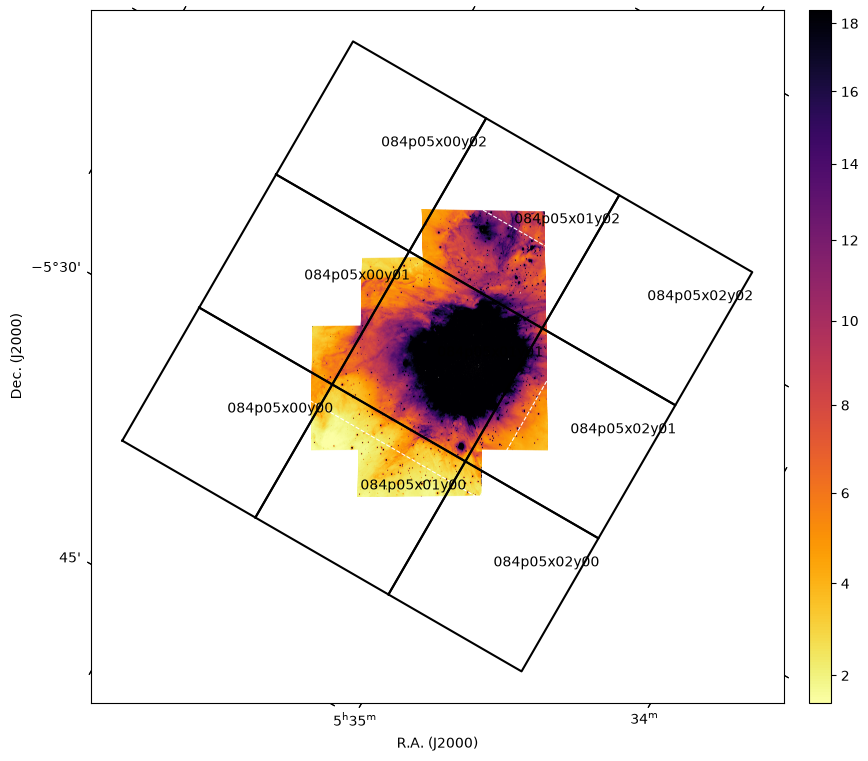

In [32]:
# Display grid of skycells on the mosaic

import matplotlib.pyplot as plt
import roman_datamodels as rdm
from astropy import visualization
from astropy.table import Table
import numpy as np
from astropy.wcs.utils import proj_plane_pixel_scales as ppps

filename = 'Orion_f213_coadd.asdf'

with rdm.open(filename) as dm:
    wcs = dm.meta.wcs
    meta = dm.meta
    data = dm.data.copy()
    hdr = dm.meta.wcs.to_fits()[0]
    print('Pixel scale ', dm.meta.resample['pixel_scale_ratio'],' pixels')

from astropy.wcs import WCS
wcs = WCS(hdr)
print('Pixel scale from wcs ', ppps(wcs)*3600, ' arcsec')
print('size of skycell: ', np.shape(data))

norm = visualization.ImageNormalize(data,
                                    interval=visualization.ZScaleInterval(contrast=1),
                                    stretch=visualization.AsinhStretch(a=1))

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw={'projection':wcs})

plot = ax.imshow(data, norm=norm, origin='lower',cmap='inferno_r')
ax.coords.grid(True, color='white', ls='dashed')
ax.coords[0].set_axislabel('R.A. (J2000)')
ax.coords[1].set_axislabel('Dec. (J2000)')

skyref = '/Users/dfadda/data/crds_cache/references/roman/wfi/roman_wfi_skycells_0001.asdf'
with rdm.open(skyref) as dm:
    skycells = dm.skycells.copy()
for skycell in skycells:
    rac = [skycell['ra_corn1'],skycell['ra_corn2'],skycell['ra_corn3'],skycell['ra_corn4'],skycell['ra_corn1']]
    dec = [skycell['dec_corn1'],skycell['dec_corn2'],skycell['dec_corn3'],skycell['dec_corn4'],skycell['dec_corn1']]
    plt.plot(rac, dec,color='black',transform=ax.get_transform('icrs'))
    plt.text(skycell['ra_center'], skycell['dec_center'], skycell['name'],transform=ax.get_transform('icrs'))
    print(skycell['name'],skycell['ra_center'], skycell['dec_center'])

cax = plt.axes([0.925, 0.11, 0.025,0.77 ])
plt.colorbar(mappable=plot, cax=cax)

plt.show()

In [8]:
# Tiles 
from glob import glob as gb
from romancal.pipeline import MosaicPipeline

path = '/Users/dfadda/Roman/FLO_Test/Orion/'
asnfiles = gb(path+'test*.asn')

steps = {'outlier_detection':{'skip':True},
         'skymatch':{'skip':True},
         'resample':{'resample_on_skycell':True},
         'source_catalog':{'skip':True},
        }

for asnfile in asnfiles:
    print('asnfile is: ', asnfile)
    result = MosaicPipeline.call(asnfile, 
                                 save_results=True, resample_on_skycell=True,
                                 steps=steps)

2026-10-20 15:52:10,912 - romancal.associations._association - WARNING - Cannot validate: <class 'romancal.associations._association._Association'> has no schema. Presuming OK.
2026-10-20 15:52:10,995 - CRDS - ERROR -  Error determining best reference for 'pars-mosaicpipeline'  =   Unknown reference type 'pars-mosaicpipeline'
2026-10-20 15:52:10,998 - stpipe.step - INFO - MosaicPipeline instance created.
2026-10-20 15:52:10,998 - stpipe.step - INFO - FluxStep instance created.
2026-10-20 15:52:10,999 - stpipe.step - INFO - SkyMatchStep instance created.
2026-10-20 15:52:10,999 - stpipe.step - INFO - OutlierDetectionStep instance created.
2026-10-20 15:52:11,000 - stpipe.step - INFO - ResampleStep instance created.
2026-10-20 15:52:11,000 - stpipe.step - INFO - SourceCatalogStep instance created.
2026-10-20 15:52:11,100 - stpipe.step - INFO - Step MosaicPipeline running with args ('/Users/dfadda/Roman/FLO_Test/Orion/test_084p05x01y01.asn',).
2026-10-20 15:52:11,103 - stpipe.step - INFO 

asnfile is:  /Users/dfadda/Roman/FLO_Test/Orion/test_084p05x01y01.asn


2026-10-20 15:52:11,231 - stpipe.step - INFO - Step flux running with args (<romancal.datamodels.library.ModelLibrary object at 0x10a09ee90>,).
2026-10-20 15:52:11,420 - py.warnings - WARNING - /Users/dfadda/miniconda3/envs/flo/lib/python3.14/site-packages/asdf/tags/core/ndarray.py:440: RuntimeWarning: overflow encountered in multiply
  return getattr(self._make_array(), name)(*args)

2026-10-20 15:52:13,633 - stpipe.step - INFO - Step flux done
2026-10-20 15:52:13,739 - stpipe.step - INFO - Step skymatch running with args (<romancal.datamodels.library.ModelLibrary object at 0x10a09ee90>,).
2026-10-20 15:52:13,739 - stpipe.step - INFO - Step skipped.
2026-10-20 15:52:15,018 - stpipe.step - INFO - Step outlier_detection running with args (<romancal.datamodels.library.ModelLibrary object at 0x10a09ee90>,).
2026-10-20 15:52:15,018 - stpipe.step - INFO - Step skipped.
2026-10-20 15:52:16,301 - stpipe.step - INFO - Step resample running with args (<romancal.datamodels.library.ModelLibrary o

asnfile is:  /Users/dfadda/Roman/FLO_Test/Orion/test_084p05x01y00.asn


2026-10-20 15:52:51,193 - stpipe.step - INFO - Step flux running with args (<romancal.datamodels.library.ModelLibrary object at 0x3fc4d6c40>,).
2026-10-20 15:52:51,386 - py.warnings - WARNING - /Users/dfadda/miniconda3/envs/flo/lib/python3.14/site-packages/asdf/tags/core/ndarray.py:440: RuntimeWarning: overflow encountered in multiply
  return getattr(self._make_array(), name)(*args)

2026-10-20 15:52:52,355 - stpipe.step - INFO - Step flux done
2026-10-20 15:52:52,461 - stpipe.step - INFO - Step skymatch running with args (<romancal.datamodels.library.ModelLibrary object at 0x3fc4d6c40>,).
2026-10-20 15:52:52,461 - stpipe.step - INFO - Step skipped.
2026-10-20 15:52:53,103 - stpipe.step - INFO - Step outlier_detection running with args (<romancal.datamodels.library.ModelLibrary object at 0x3fc4d6c40>,).
2026-10-20 15:52:53,104 - stpipe.step - INFO - Step skipped.
2026-10-20 15:52:53,743 - stpipe.step - INFO - Step resample running with args (<romancal.datamodels.library.ModelLibrary o

...

2026-10-20 15:53:36,932 - stpipe.step - INFO - Step flux running with args (<romancal.datamodels.library.ModelLibrary object at 0x3fb403e70>,).
2026-10-20 15:53:37,417 - stpipe.step - INFO - Step flux done
2026-10-20 15:53:37,524 - stpipe.step - INFO - Step skymatch running with args (<romancal.datamodels.library.ModelLibrary object at 0x3fb403e70>,).
2026-10-20 15:53:37,524 - stpipe.step - INFO - Step skipped.
2026-10-20 15:53:37,903 - stpipe.step - INFO - Step outlier_detection running with args (<romancal.datamodels.library.ModelLibrary object at 0x3fb403e70>,).
2026-10-20 15:53:37,903 - stpipe.step - INFO - Step skipped.
2026-10-20 15:53:38,280 - stpipe.step - INFO - Step resample running with args (<romancal.datamodels.library.ModelLibrary object at 0x3fb403e70>,).
2026-10-20 15:53:38,281 - romancal.resample.resample - INFO - Skycell record: [('084p05x00y02', 84.01036357, -5.24589813, -0.15341948, 7499.5, -2500.5, 84.08710162, -5.32226271, 83.93366364, -5.32230066, 83.93364431, -5

asnfile is:  /Users/dfadda/Roman/FLO_Test/Orion/test_084p05x00y00.asn


2026-10-20 15:53:40,415 - py.warnings - WARNING - /Users/dfadda/miniconda3/envs/flo/lib/python3.14/site-packages/asdf/tags/core/ndarray.py:440: RuntimeWarning: overflow encountered in multiply
  return getattr(self._make_array(), name)(*args)

2026-10-20 15:53:40,627 - stpipe.step - INFO - Step flux done
2026-10-20 15:53:40,736 - stpipe.step - INFO - Step skymatch running with args (<romancal.datamodels.library.ModelLibrary object at 0x303371190>,).
2026-10-20 15:53:40,736 - stpipe.step - INFO - Step skipped.
2026-10-20 15:53:41,035 - stpipe.step - INFO - Step outlier_detection running with args (<romancal.datamodels.library.ModelLibrary object at 0x303371190>,).
2026-10-20 15:53:41,036 - stpipe.step - INFO - Step skipped.
2026-10-20 15:53:41,331 - stpipe.step - INFO - Step resample running with args (<romancal.datamodels.library.ModelLibrary object at 0x303371190>,).
2026-10-20 15:53:41,332 - romancal.resample.resample - INFO - Skycell record: [('084p05x00y00', 84.01044092, -5.5514518

asnfile is:  /Users/dfadda/Roman/FLO_Test/Orion/test_084p05x00y01.asn


2026-10-20 15:53:43,455 - stpipe.step - INFO - Step flux running with args (<romancal.datamodels.library.ModelLibrary object at 0x301cf3750>,).
2026-10-20 15:53:43,647 - py.warnings - WARNING - /Users/dfadda/miniconda3/envs/flo/lib/python3.14/site-packages/asdf/tags/core/ndarray.py:440: RuntimeWarning: overflow encountered in multiply
  return getattr(self._make_array(), name)(*args)

2026-10-20 15:53:44,628 - stpipe.step - INFO - Step flux done
2026-10-20 15:53:44,737 - stpipe.step - INFO - Step skymatch running with args (<romancal.datamodels.library.ModelLibrary object at 0x301cf3750>,).
2026-10-20 15:53:44,738 - stpipe.step - INFO - Step skipped.
2026-10-20 15:53:45,414 - stpipe.step - INFO - Step outlier_detection running with args (<romancal.datamodels.library.ModelLibrary object at 0x301cf3750>,).
2026-10-20 15:53:45,414 - stpipe.step - INFO - Step skipped.
2026-10-20 15:53:46,090 - stpipe.step - INFO - Step resample running with args (<romancal.datamodels.library.ModelLibrary o

## Rebuilding the mosaic

In [9]:
from glob import glob as gb
from flo.mosaic import stitchCells

path = '/Users/dfadda/Roman/FLO_Test/Orion/'
asdffiles = gb(path+'_test*.asdf')

stitchCells(asdffiles, outname='Orion_NE')

Pixel scale from wcs  [0.11 0.11]  arcsec
size of image:  (15000, 15000)


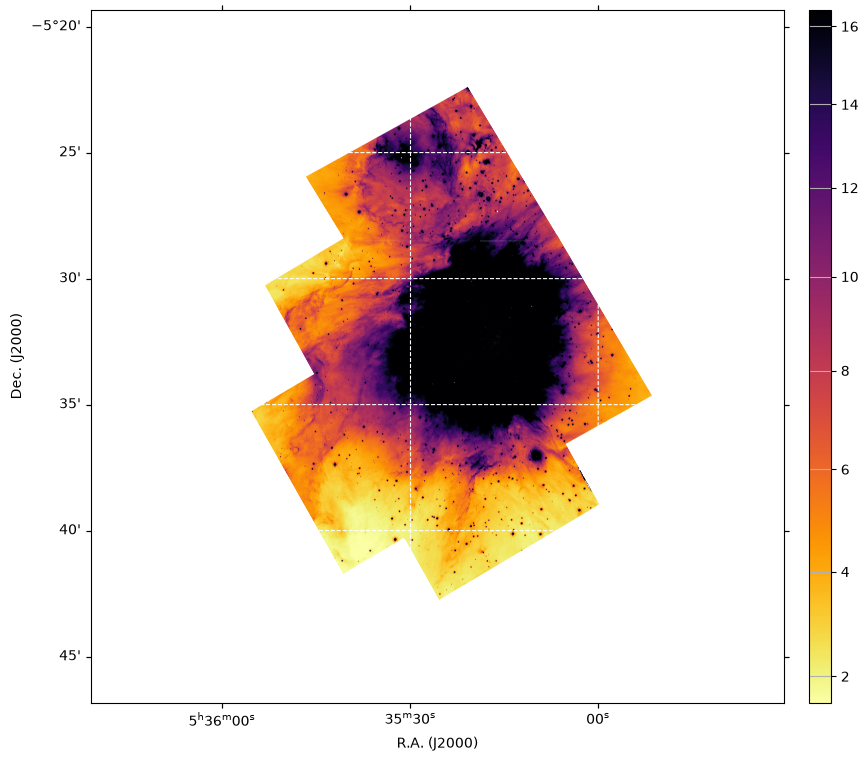

In [10]:
# Display mosaic
import matplotlib.pyplot as plt
import roman_datamodels as rdm
from astropy import visualization
from astropy.table import Table
import numpy as np
from astropy.wcs.utils import proj_plane_pixel_scales as ppps
from astropy.wcs import WCS
from astropy.io import fits

with fits.open('Orion_NE.fits') as f:
    image = f[0].data
    header = f[0].header

wcs = WCS(header)

#wcs = WCS(hdr)
print('Pixel scale from wcs ', ppps(wcs)*3600, ' arcsec')
print('size of image: ', np.shape(image))


norm = visualization.ImageNormalize(image,
                                    interval=visualization.ZScaleInterval(contrast=1),
                                    stretch=visualization.AsinhStretch(a=1))

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw={'projection':wcs})

plot = ax.imshow(image, norm=norm,  origin='lower',cmap='inferno_r')
ax.coords.grid(True, color='white', ls='dashed')
ax.coords[0].set_axislabel('R.A. (J2000)')
ax.coords[1].set_axislabel('Dec. (J2000)')

cax = plt.axes([0.925, 0.11, 0.025,0.77 ])
plt.colorbar(mappable=plot, cax=cax)
plt.grid()
plt.show()

# Other issues

## Striping

Sdf software version  2026.2.3
Cal software version  1.2.0.dev46+gdecbcb896
CRDS context  roman_0075.pmap
Cal steps:  {'assign_wcs': 'COMPLETE', 'dark': 'COMPLETE', 'dark_decay': 'COMPLETE', 'dq_init': 'COMPLETE', 'flat_field': 'COMPLETE', 'flux': 'INCOMPLETE', 'linearity': 'COMPLETE', 'outlier_detection': 'INCOMPLETE', 'photom': 'COMPLETE', 'ramp_fit': 'COMPLETE', 'refpix': 'COMPLETE', 'saturation': 'COMPLETE', 'skymatch': 'INCOMPLETE', 'source_catalog': 'COMPLETE', 'tweakreg': 'COMPLETE', 'wfi18_transient': 'N/A'}


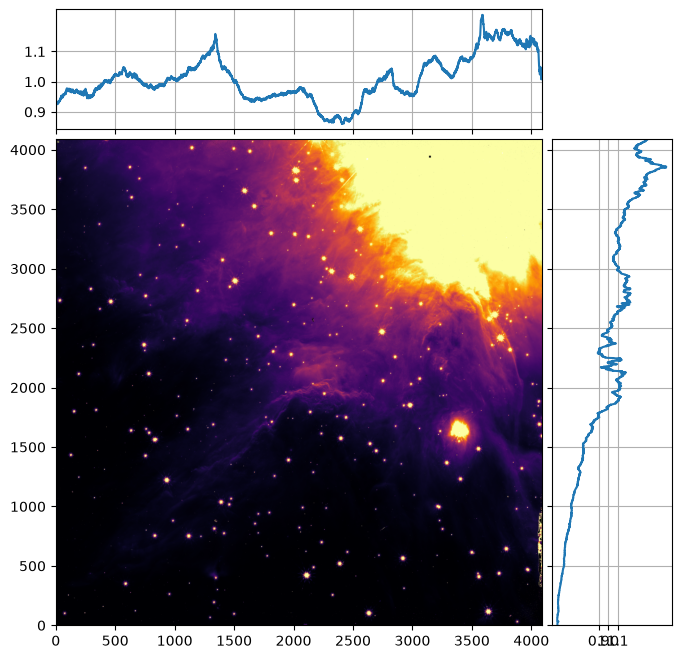

In [4]:
# Check striping

import matplotlib.pyplot as plt
import numpy as np

from mpl_toolkits.axes_grid1 import make_axes_locatable
import roman_datamodels as rd
from roman_datamodels.dqflags import pixel
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.pyplot as plt
from astropy.visualization import PercentileInterval
import numpy as np

path = '/Users/dfadda/Roman/FLO_Test/Orion/'
file = path+'r0108303005001001007_0001_wfi07_f213_cal.asdf'
with rd.open(file) as dm:
    data = dm.data.copy()
    dq = dm.dq.copy()
    err = dm.err.copy()
    meta = dm.meta.copy()

print('Sdf software version ', meta.sdf_software_version)
print('Cal software version ', meta.calibration_software_version)
print('CRDS context ', meta.ref_file.crds.context)
print('Cal steps: ', meta.cal_step)


percentile = 80
interval = PercentileInterval(percentile)



fig, ax = plt.subplots(figsize=(8,8))
vmin, vmax = interval.get_limits(data)
ax.imshow(data, vmin=vmin, vmax=vmax, cmap='inferno', origin='lower')

# Set aspect of the main Axes.
ax.set_aspect(1.)

# create new Axes on the right and on the top of the current Axes
divider = make_axes_locatable(ax)
# below height and pad are in inches
ax_x = divider.append_axes("top", 1.2, pad=0.1, sharex=ax)
ax_y = divider.append_axes("right", 1.2, pad=0.1, sharey=ax)

# make some labels invisible
ax_x.xaxis.set_tick_params(labelbottom=False)
ax_y.yaxis.set_tick_params(labelleft=False)

# now determine nice limits by hand:
# Subtract median (row and columns)
med = np.nanmedian(data)
mad = np.nanmedian(np.abs(data-med))*1.4826
ndata = data.copy()
idx = np.abs(ndata - med) > 1.5 * mad
ndata[idx]=np.nan
mrow = np.nanmedian(ndata, axis=1)
mrow /= np.nanmedian(mrow)
ndata = data / mrow[:, np.newaxis]
ndata[idx]=np.nan
mcol = np.nanmedian(ndata[:500,:], axis=0)
mcol /= np.nanmedian(mcol)


ax_x.plot(mcol)
ax_y.plot(mrow,np.arange(4088))

ax_x.set_yticks([0.9, 1, 1.1])
ax_x.grid()
ax_y.set_xticks([0.9, 1, 1.1])
ax_y.grid()

plt.show()

In [ ]:
# Let's compute a background and subtract it
import numpy as np
from scipy import ndimage
import roman_datamodels as rd


path = '/Users/dfadda/Roman/FLO_Test/Orion/'
file = path+'r0108303005001001007_0001_wfi07_f213_cal.asdf'
with rd.open(file) as dm:
    data = dm.data.copy()
    dq = dm.dq.copy()
    err = dm.err.copy()
    meta = dm.meta.copy()

# Apply a 3x3 boxcar median filter
filtered_data = ndimage.median_filter(data, size=10)


(2600.0, 3000.0)

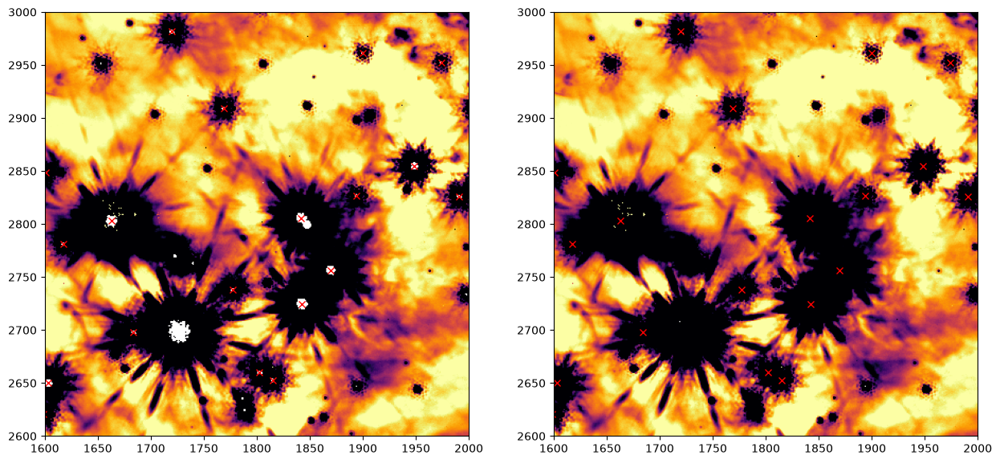

In [3]:
from photutils.background import Background2D, MedianBackground
import roman_datamodels as rd
from roman_datamodels.dqflags import pixel    
from maskfill import maskfill
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
from astropy.visualization import PercentileInterval


path = '/Users/dfadda/Roman/FLO_Test/Orion/Offset/'
file = path+'r0108303005001001002_0002_wfi16_f213_off_cal.asdf'
with rd.open(file) as dm:
    data = dm.data.copy()
    dq = dm.dq.copy()
    err = dm.err.copy()
    meta = dm.meta.copy()
file = path+'r0108303005001001002_0002_wfi16_f213_off_cal_us.asdf'
with rd.open(file) as dm:
    udata = dm.data.copy()

    
    
data0 = data.copy()

idx = (dq == pixel.DO_NOT_USE.value) != 0
mask1 = np.zeros(np.shape(data))
data0[idx]=np.nan
mask1[idx] = 1
idx = (data < 0)
data0[idx]=np.nan
mask1[idx] = 1
#data0,_ = maskfill(data0, mask1, operator='median' )

block = 50
bkg_estimator = MedianBackground()
bkg = Background2D(data0, (block,block), filter_size=(3,3), bkg_estimator=bkg_estimator,exclude_percentile=12.0)

#plt.imshow(bkg.background, vmin=vmin, vmax=vmax, cmap='inferno', origin='lower')

percentile = 98
interval = PercentileInterval(percentile)
bdata = data - bkg.background
ubdata = udata - bkg.background
fig, (ax1, ax2) = plt.subplots(1,2,figsize=(15,15))
vmin, vmax = interval.get_limits(bdata)
ax1.imshow(bdata, vmin=vmin, vmax=vmax, cmap='inferno_r', origin='lower')
ax2.imshow(ubdata, vmin=vmin, vmax=vmax, cmap='inferno_r', origin='lower')


# Desaturate the PSFs
from astropy.coordinates import SkyCoord
from astropy.table import Table

path = '/Users/dfadda/Roman/FLO_Test/Orion/'
ufile = 'r0108303005001001002_0002_wfi16_f213'

#gaia_catalog = Table.read(path + 'MAST_2026-10-09T1317/Roman/'+ufile + '_gaiadr3.ecsv')
#idx = np.isnan(gaia_catalog['aper01_flux'].value)
#gaia_catalog = gaia_catalog[idx]
#stars = SkyCoord(gaia_catalog['ra'].value, gaia_catalog['dec'].value, unit='deg', frame = 'icrs')
gaia_catalog = Table.read('gaia_catalog.ecsv')
stars = SkyCoord(gaia_catalog['ra'].value, gaia_catalog['dec'].value, unit='deg', frame = 'icrs')
wcs = meta.wcs
x,y = wcs.backward_transform(gaia_catalog['ra'].value, gaia_catalog['dec'].value)
ax1.plot(x, y, 'x',color='red')
ax2.plot(x, y, 'x',color='red')
xc, yc = 1800, 2800
dd = 200
ax1.set_xlim(xc-dd,xc+dd)
ax1.set_ylim(yc-dd, yc+dd)
ax2.set_xlim(xc-dd,xc+dd)
ax2.set_ylim(yc-dd, yc+dd)
#print('x ',gaia_catalog['x'].value)
#print('y ',gaia_catalog['y'].value)


In [3]:
from scipy.ndimage import label, find_objects
import numpy as np

# Not corrected and saturated
nan_mask = np.isnan(ubdata) & ((dq & pixel.SATURATED.value) != 0)


labeled_mask, num_features = label(nan_mask)
print(f"Found {num_features} distinct NaN clusters.")
slices = find_objects(labeled_mask)
xb, yb = [], []
xx, yy = np.arange(4088), np.arange(4088)
X, Y = np.meshgrid(xx, yy)
minarea = 1
n = 0
for i, sl in enumerate(slices):
    if sl is not None:
        #print(f"Cluster {i+1} bounding box slices: Y-range {sl[0]}, X-range {sl[1]}")
        yi, ye = sl[0].start, sl[0].stop
        xi, xe = sl[1].start, sl[1].stop
        if (xe-xi)*(ye-yi) > minarea:
            # Find barycenter of the cluster
            idnan = np.where(nan_mask[yi:ye, xi:xe] == 1)
            bX, bY = X[yi:ye, xi:xe], Y[yi:ye, xi:xe]
            yb.append(np.mean(bY[idnan]))
            xb.append(np.mean(bX[idnan]))
            n += 1
print(f'Found {n} clusters with at least {minarea} points')
xb, yb = np.array(xb), np.array(yb)

idx = (xb >= 17) & (xb < 4088-17) & (yb >= 17) & (yb < 4088-17)  
        

Found 103 distinct NaN clusters.
Found 7 clusters with at least 1 points


(2100.0, 2900.0)

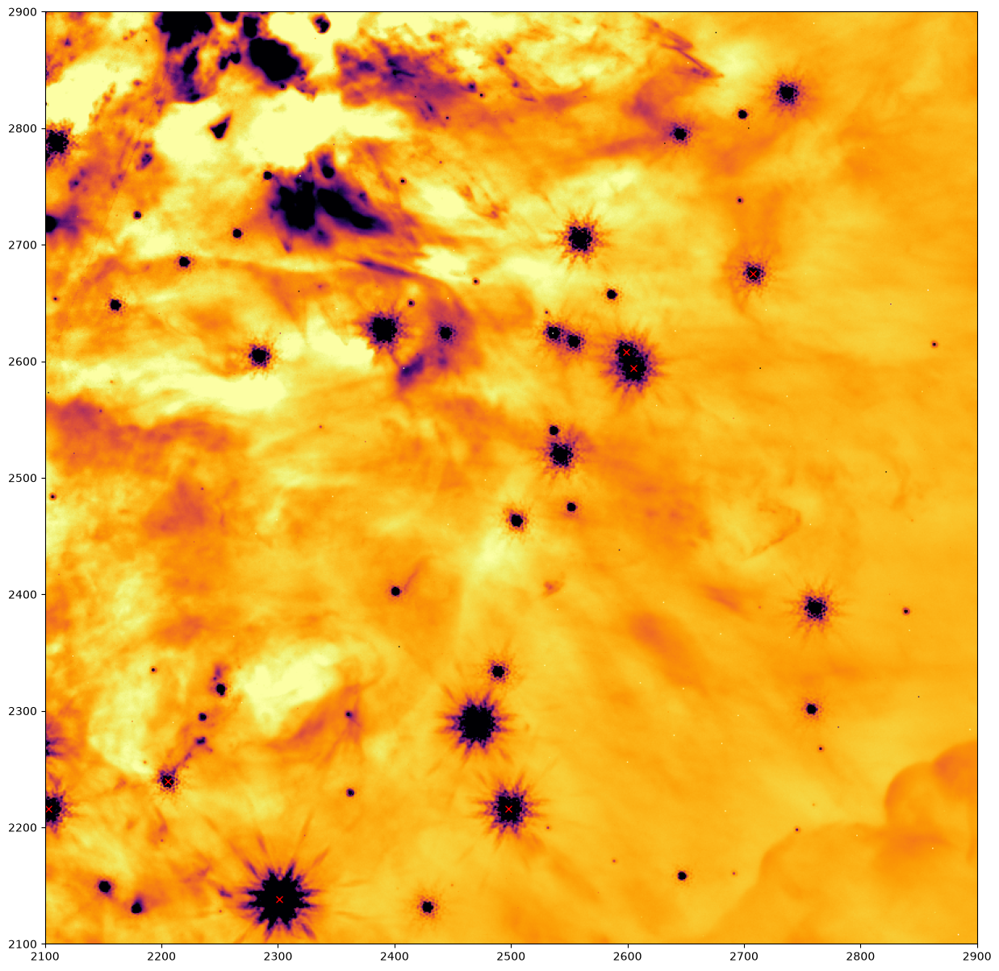

In [8]:
fig, ax = plt.subplots(figsize=(15,15))
vmin, vmax = interval.get_limits(bdata)
ax.imshow(ubdata, vmin=vmin, vmax=vmax, cmap='inferno_r', origin='lower')
ax.plot(xb, yb, 'x',color='blue')
x,y = wcs.backward_transform(gaia_catalog['ra'].value, gaia_catalog['dec'].value)
ax.plot(x, y, 'x',color='red')

xc, yc = 2500, 2500
dd = 400
ax.set_xlim(xc-dd,xc+dd)
ax.set_ylim(yc-dd, yc+dd)


# Pixel Area Map

In [3]:
import roman_datamodels as rdm
import crds

path = '/Users/dfadda/Roman/FLO_Test/Orion/'
file = path+'r0108303005001001007_0001_wfi07_f213_cal.asdf'

with rdm.open(file) as dm:
    meta = dm.meta.copy()

print('Get references')
crds_result = crds.getreferences({'ROMAN.META.INSTRUMENT.DETECTOR': meta.instrument.detector,
                                  'ROMAN.META.INSTRUMENT.NAME': meta.instrument.name,
                                  'ROMAN.META.EXPOSURE.START_TIME': meta.exposure.start_time.isot}, 
                                 observatory='roman', reftypes=['area'], ignore_cache=True)

CRDS - INFO -  Syncing 31 files
CRDS - INFO -  Fetching  /Users/dfadda/data/crds_cache/mappings/roman/roman_wfi_specpsf_0002.rmap      787 bytes  (1 / 31 files) (0 / 111.1 K bytes)
CRDS - INFO -  Fetching  /Users/dfadda/data/crds_cache/mappings/roman/roman_wfi_skycells_0002.rmap      712 bytes  (2 / 31 files) (787 / 111.1 K bytes)


Get references


CRDS - INFO -  Fetching  /Users/dfadda/data/crds_cache/mappings/roman/roman_wfi_sflat_0002.rmap      759 bytes  (3 / 31 files) (1.5 K / 111.1 K bytes)
CRDS - INFO -  Fetching  /Users/dfadda/data/crds_cache/mappings/roman/roman_wfi_saturation_0004.rmap    3.6 K bytes  (4 / 31 files) (2.3 K / 111.1 K bytes)
CRDS - INFO -  Fetching  /Users/dfadda/data/crds_cache/mappings/roman/roman_wfi_relflux_0002.rmap      770 bytes  (5 / 31 files) (5.9 K / 111.1 K bytes)
CRDS - INFO -  Fetching  /Users/dfadda/data/crds_cache/mappings/roman/roman_wfi_refpix_0005.rmap    2.3 K bytes  (6 / 31 files) (6.6 K / 111.1 K bytes)
CRDS - INFO -  Fetching  /Users/dfadda/data/crds_cache/mappings/roman/roman_wfi_readnoise_0008.rmap    3.8 K bytes  (7 / 31 files) (9.0 K / 111.1 K bytes)
CRDS - INFO -  Fetching  /Users/dfadda/data/crds_cache/mappings/roman/roman_wfi_photom_0006.rmap    3.4 K bytes  (8 / 31 files) (12.8 K / 111.1 K bytes)
CRDS - INFO -  Fetching  /Users/dfadda/data/crds_cache/mappings/roman/roman_wfi_

Open pam file
(4088, 4088)
Zeropoint = 1.1102914810180664 (MJy/sr) / (DN/s)
Nominal pixel area = 0.011841732683592702 sr
0.10881972561807304


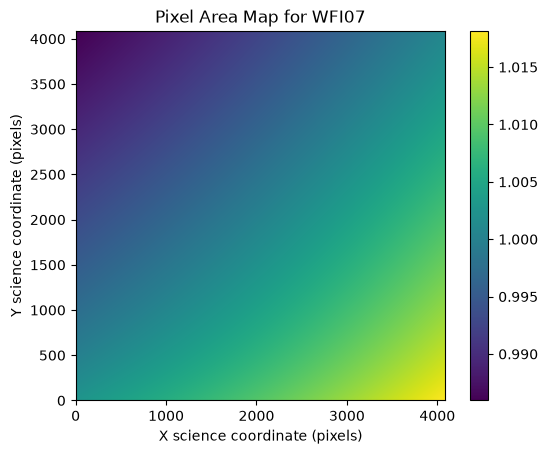

In [5]:
import matplotlib.pyplot as plt
import numpy as np

print('Open pam file')
with rdm.open(crds_result['area']) as pam:
    pamdata = pam.data.copy()

print(np.shape(pamdata))
zpt = meta.photometry.conversion_megajanskys
pixel_area = meta.photometry.pixel_area * (180/np.pi)**2 *3600**2

print(f'Zeropoint = {zpt} (MJy/sr) / (DN/s)')
print(f'Nominal pixel area = {pixel_area} sr')
print(np.sqrt(pixel_area))

fig, ax = plt.subplots()
img = ax.imshow(1/pamdata, origin='lower')
ax.set_xlabel('X science coordinate (pixels)')
ax.set_ylabel('Y science coordinate (pixels)')
ax.set_title(f'Pixel Area Map for {pam.meta.instrument.detector}')
plt.colorbar(img)
plt.show()

In [6]:
idx = np.isnan(pamdata)
print(np.sum(idx))

0


In [139]:
from astropy.modeling import models
from astropy import coordinates as coord
from astropy import units as u
from gwcs import wcs
from gwcs import coordinate_frames as cf

npix = 5000
ncol = np.ceil(np.ceil(nx)/npix)
nrow = np.ceil(np.ceil(ny)/npix)
print(np.ceil(nx)/npix, np.ceil(ny)/npix)
# Make them odd numbers to center first cell at 0,0
ncol = int(ncol // 2 * 2 + 1)
nrow = int(nrow // 2 * 2 + 1)
print(ncol, type(ncol))

# Build cells
col, row = np.indices((ncol, nrow))

col -= ncol//2
row -= nrow//2
print(row)
print(col)

# Compute nx, ny
nx = ncol * npix
ny = nrow * npix
x0t, y0t = (nx-1)/2 , (ny-1)/2
pix = pixscale / 3600.
pixelshift = models.Shift(-x0t) & models.Shift(-y0t)
pixelscale = models.Scale(-pix) & models.Scale(pix) # 0.1 arcsec/pixel
tangent_projection = models.Pix2Sky_TAN()
celestial_rotation = models.RotateNative2Celestial(crval1, crval2, 180.)
det2sky = pixelshift | pixelscale | tangent_projection | celestial_rotation
detector_frame = cf.Frame2D(name="detector", axes_names=("x", "y"), unit=(u.pix, u.pix))
sky_frame = cf.CelestialFrame(reference_frame=coord.ICRS(), name='icrs', unit=(u.deg, u.deg))
wcsobj = wcs.WCS([(detector_frame, det2sky),(sky_frame, None)])


print('center of tile ', x0t, y0t)

# 
x0, y0 = col * npix + x0t, row * npix + y0t
# Cell corners
hcellsize = npix // 2 
x1, y1 = x0 - hcellsize, y0 - hcellsize
x2, y2 = x0 + hcellsize, y0 - hcellsize
x3, y3 = x0 + hcellsize, y0 + hcellsize
x4, y4 = x0 - hcellsize, y0 + hcellsize

a0, d0 = wcsobj(x0, y0)
a1, d1 = wcsobj(x1, y1)
a2, d2 = wcsobj(x2, y2)
a3, d3 = wcsobj(x3, y3)
a4, d4 = wcsobj(x4, y4)

# For each cell, define cell and list the images overlapping the cell

for i in range(nrow):
    for j in range(ncol):

        pcell = [(a1[i,j],d1[i,j]),(a2[i,j],d2[i,j]),(a3[i,j],d3[i,j]),(a4[i,j],d4[i,j])]
        members = []
        # Find the overlapping images
        for ra_, dec_, file in zip(ra, dec, files):
            pimage = [(ra_[k],dec_[k]) for k in range(4)]
            if convex_polygons_intersect(pcell, pimage):
                members.append(file)
        print(i,j,members)

3.0 3.0
3 <class 'int'>
[[-1  0  1]
 [-1  0  1]
 [-1  0  1]]
[[-1 -1 -1]
 [ 0  0  0]
 [ 1  1  1]]
center of tile  7499.5 7499.5
0 0 ['/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001007_0002_wfi07_f213_off_cal_us_ok.asdf']
0 1 ['/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001007_0002_wfi07_f213_off_cal_us_ok.asdf', '/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001006_0001_wfi09_f213_off_cal_us_ok.asdf', '/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001002_0003_wfi16_f213_off_cal_us_ok.asdf']
0 2 ['/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001003_0002_wfi18_f213_off_cal_us_ok.asdf']
1 0 ['/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001007_0001_wfi07_f213_off_cal_us_ok.asdf', '/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001002_0002_wfi16_f213_off_cal_us_ok.asdf', '/Users/dfadda/Roman/FLO_Test/Orion/Offset/r0108303005001001007_0002_wfi07_f213_off_cal_us_ok.asdf']
1 1 ['/Users/dfadda/Roman/FLO_Test/Orion/Off

# Using alternative reference file

In [8]:
# search for reference file
import crds

import roman_datamodels as rdm
import crds

path = '/Users/dfadda/Roman/FLO_Test/Orion/'
file = path+'r0108303005001001007_0001_wfi07_f213_cal.asdf'

with rdm.open(file) as dm:
    meta = {'ROMAN.META.INSTRUMENT.NAME': 'WFI',
        'ROMAN.META.INSTRUMENT.DETECTOR': dm.meta.instrument.detector,
        'ROMAN.META.EXPOSURE.START_TIME': dm.meta.exposure.start_time.iso,
        'ROMAN.META.INSTRUMENT.OPTICAL_ELEMENT': dm.meta.instrument.optical_element,
       }

ref_files = crds.getreferences(meta, reftypes=['skymap'], observatory='roman')
ref_files

2026-10-19 22:05:50,544 - CRDS - ERROR -  Error determining best reference for 'skymap'  =   Unknown reference type 'skymap'


CrdsLookupError: Error determining best reference for 'skymap'  =   Unknown reference type 'skymap'

In [138]:
rcal = ELP(steps={'dq_init': {'override_mask': ref_files['mask']},
                 'assign_wcs': {'override_distortion': ref_files['distortion']}})
rcal.call('r0103301003001001001_0001_wfi15_f146_uncal.asdf')

array([-1, -1, -1])